# BANKING77 Topic Discovery – Pipeline v3 (có đánh giá tích hợp)

**Pipeline:** Light cleaning → Sentence encoder → UMAP 5D → HDBSCAN → c-TF-IDF (sửa lỗi) → Novelty score (kNN)

Notebook này khác bản gốc ở 3 điểm:

- **Đánh giá là một phần của pipeline**, không phải notebook thí nghiệm rời: mọi phương pháp đi qua cùng một bộ đo (external + structure + internal + bootstrap).
- **Mỗi lựa chọn thiết kế có bằng chứng đi kèm** (ghi ở đầu mỗi phần) và được **tính lại ngay trong notebook** để bạn kiểm chứng trên máy mình.
- **Luận điểm "noise = emerging topic" được kiểm định riêng** (Phần 8) thay vì giả định, và có thêm một detector thay thế (kNN novelty) để so sánh.

Nhãn thật (`label`) **không** dùng khi clustering; chỉ dùng trong các hàm đánh giá.

In [1]:
!pip install -q sentence-transformers umap-learn hdbscan

## 0. Tham số và import

Các giá trị mặc định lấy từ kết quả thí nghiệm của bạn (B3: encoder, B4: `min_cluster_size`/`eom`, A1: UMAP 5D).
Chỉ sửa trong `Cfg`; mọi phần phía sau đọc từ `CFG`.

In [2]:
%matplotlib inline
import re, html, itertools, warnings, os
from dataclasses import dataclass, asdict
import numpy as np, pandas as pd
import umap, hdbscan
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.metrics import (adjusted_rand_score as ARI, normalized_mutual_info_score as NMI,
                             adjusted_mutual_info_score as AMI, homogeneity_score as HOM,
                             completeness_score as COMP, v_measure_score as V,
                             silhouette_score, roc_auc_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
warnings.filterwarnings('ignore')

@dataclass
class Cfg:
    encoder: str = 'BAAI/bge-small-en-v1.5'   # B3: V 0.832 vs 0.788 (MiniLM), cùng 384D
    n_neighbors: int = 30                     # UMAP
    n_components: int = 5                     # A1/B4: bỏ UMAP -> noise 49%; 10D không tốt hơn 5D
    min_cluster_size: int = 50                # B4
    min_samples: int = 5
    selection: str = 'eom'                    # B4: leaf tăng noise 9% -> 16%
    seed: int = 42
    n_seeds: int = 5                          # kiểm tra độ ổn định
    knn_k: int = 10                           # novelty score
    novelty_pct: float = 95.0                 # ngưỡng novelty = phân vị 95 của train
    n_keywords: int = 8
    noise_mcs: int = 8                        # gom nhóm trong tập noise
    emerge_mcs: int = 8                       # gom nhóm trong tập bị gắn cờ "mới"

CFG = Cfg()
BASELINE_ENCODER = 'sentence-transformers/all-MiniLM-L6-v2'   # encoder của pipeline gốc
BENCH_ENCODERS = {'MiniLM-L6 (gốc)': BASELINE_ENCODER,
                  'BGE-small': 'BAAI/bge-small-en-v1.5',
                  'MPNet-base': 'sentence-transformers/all-mpnet-base-v2'}
INCLUDE_NO_UMAP = True      # ablation A1 chạy HDBSCAN 384D khá chậm; đặt False để bỏ qua


## 1. Dữ liệu và embedding

Upload `train.csv`, `test.csv` (cột `text`, `label`, `label_text`) hoặc đặt sẵn cạnh notebook.

In [3]:
def light_clean(t):
    t = html.unescape(str(t)); t = re.sub(r'<[^>]+>', ' ', t)
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t); t = re.sub(r'\S+@\S+\.\S+', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def load_data():
    import glob
    # 1. Tìm kiếm tự động train.csv trong mọi thư mục con của /kaggle/input hoặc thư mục hiện tại
    found = glob.glob('/kaggle/input/**/train.csv', recursive=True) + glob.glob('**/train.csv', recursive=True)
    if not found:
        listing = []
        if os.path.exists('/kaggle/input'):
            for r, d, f in os.walk('/kaggle/input'):
                listing.append(f"{r}: {f}")
        raise FileNotFoundError(f"Không tìm thấy train.csv! Cấu trúc /kaggle/input hiện có: {listing}")

    tr_path = found[0]
    te_path = tr_path.replace('train.csv', 'test.csv')
    print(f"[+] Đã tìm thấy file dữ liệu:")
    print(f"    - Train: {tr_path}")
    print(f"    - Test:  {te_path}")
    tr = pd.read_csv(tr_path, encoding='utf-8-sig'); te = pd.read_csv(te_path, encoding='utf-8-sig')
    for d in (tr, te): d['clean'] = d.text.map(light_clean)
    return tr, te

train, test = load_data()
y_tr, y_te = train.label.values, test.label.values
K_TRUE = len(np.unique(y_tr))
print(f"[+] Loaded: {len(train)} train | {len(test)} test | {K_TRUE} intents")

_EMB, _MODELS = {}, {}
def embed(texts, model_name, tag):
    # Cache theo (model, tag) để mỗi encoder chỉ chạy 1 lần trên mỗi tập.
    if (model_name, tag) not in _EMB:
        from sentence_transformers import SentenceTransformer
        import torch
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
        m = _MODELS.setdefault(model_name, SentenceTransformer(model_name, device=device))
        _EMB[(model_name, tag)] = m.encode(list(texts), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    return _EMB[(model_name, tag)]

X_tr = embed(train.clean, CFG.encoder, 'train'); X_te = embed(test.clean, CFG.encoder, 'test')
print(f"[+] Embeddings ready: X_tr={X_tr.shape}, X_te={X_te.shape}")


Saving test.csv to test.csv
Saving train.csv to train.csv
9993 train | 3076 test | 77 intent


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

(9993, 384)


## 2. Pipeline (class) – lý do từng bước

| Bước | Lựa chọn | Lý do (bằng chứng từ thí nghiệm của bạn) |
|---|---|---|
| Cleaning | Chỉ HTML/URL/email/khoảng trắng, **không** bỏ stopword | Encoder dùng toàn bộ ngữ cảnh câu; từ như *not*, *why* đổi nghĩa intent |
| Encoder | **BGE-small** (mặc định) | B3: V 0.832 / ARI 0.541 vs MiniLM 0.788 / 0.440, noise 7.3% vs 9.1%, cùng 384D nên chi phí tương đương. MPNet (768D) chậm gấp đôi mà kém BGE |
| Giảm chiều | UMAP 5D, cosine, **fit train – transform test** | A1: bỏ UMAP thì noise 9% → 49%, V 0.788 → 0.539 (HDBSCAN suy yếu ở 384D). UMAP 10D không hơn (V bỏ noise 0.828 < 0.838). Fit riêng trên train để không rò rỉ test |
| Clustering | HDBSCAN `eom`, `min_cluster_size=50`, `min_samples=5` | B4: `leaf` tăng noise lên 13–17%; `mcs=20/30` chẻ thành 120–183 cụm. `mcs=50` ≈ 1/3 kích thước 1 intent (~130 câu) nên cụm nhỏ nhất vẫn có ý nghĩa. Không cần biết trước K |
| Gán lại noise | **Không dùng** | B2: câu gán lại chỉ đúng 36%, ARI (cả noise) tăng nhờ giảm noise nhưng đổi bằng chất lượng cụm |
| Novelty | **kNN cosine distance** trong không gian embedding gốc, ngưỡng = phân vị 95 train | Giả thuyết cần kiểm chứng ở Phần 8: noise của HDBSCAN phụ thuộc mật độ sau UMAP nên không đo trực tiếp "xa dữ liệu đã biết". Kết quả C của bạn (recall ≈ tỉ lệ noise ở dữ liệu cũ) cho thấy cần một detector khác |
| Keyword | c-TF-IDF tính **theo từng câu**, có `min_support`, `max_df` | Lỗi cũ: ghép các câu bằng dấu cách nên sinh bigram vắt qua ranh giới câu (`pin pin`, `refund refund`, `beneficiary beneficiary`) |

In [4]:
EXTRA_STOP = {'didn','don','hasn','isn','doesn','wasn','won','ve','ll','just','like','want','need','know',
              'tell','able','think','tried','help','today','yesterday','ago'}
STOP = list(ENGLISH_STOP_WORDS | EXTRA_STOP)

def c_tfidf_keywords(texts, labels, n=8, max_df=0.3, min_support=0.03):
    # c-TF-IDF: mỗi cụm = 1 "văn bản lớn".
    # Khác bản gốc: n-gram đếm TRONG TỪNG CÂU (không vắt qua ranh giới câu) và đếm số câu chứa n-gram.
    texts, labels = np.asarray(texts), np.asarray(labels)
    ids = sorted(set(labels) - {-1}); assigned = np.where(labels != -1)[0]
    cv = CountVectorizer(stop_words=STOP, ngram_range=(1, 2), binary=True, min_df=2,
                         token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
    C = cv.fit_transform(texts).tocsr()
    M = sparse.csr_matrix((np.ones(len(assigned)), (np.searchsorted(ids, labels[assigned]), assigned)),
                          shape=(len(ids), len(texts)))
    CC = (M @ C).toarray().astype(float)                       # cụm x n-gram: số câu chứa n-gram
    sizes = np.asarray(M.sum(1)).ravel()
    CC[:, (CC > 0).mean(0) > max_df] = 0                       # bỏ n-gram xuất hiện ở > max_df số cụm
    CC[CC < np.maximum(3, min_support * sizes)[:, None]] = 0   # bỏ n-gram hiếm trong cụm
    tf = CC / np.maximum(CC.sum(1, keepdims=True), 1)
    idf = np.log(1 + (CC.sum() / len(ids)) / np.maximum(CC.sum(0), 1))
    words, score, out = cv.get_feature_names_out(), tf * idf, {}
    for i, t in enumerate(ids):
        chosen = []
        for j in np.argsort(-score[i]):
            if score[i, j] <= 0 or len(chosen) >= n: break
            tok = words[j].split()
            if len(tok) == 2 and tok[0] == tok[1]: continue    # loại 'pin pin'
            chosen.append(words[j])
        out[t] = ', '.join(chosen)
    return out

class TopicPipeline:
    # fit(X) -> cụm + keyword + chỉ mục kNN;  predict(X) -> topic, strength, novelty, flag.
    def __init__(self, cfg): self.cfg = cfg

    def _fit_cluster(self, X):
        c = self.cfg
        self.reducer = umap.UMAP(n_neighbors=c.n_neighbors, n_components=c.n_components, min_dist=0.0,
                                 metric='cosine', random_state=c.seed).fit(X)
        self.Z = self.reducer.embedding_
        self.clusterer = hdbscan.HDBSCAN(min_cluster_size=c.min_cluster_size, min_samples=c.min_samples,
                                         cluster_selection_method=c.selection, prediction_data=True,
                                         gen_min_span_tree=True).fit(self.Z)
        self.labels = self.clusterer.labels_
        return self

    def fit(self, X, texts=None, keywords=True):
        c = self.cfg
        self._fit_cluster(X)
        self.keywords = c_tfidf_keywords(texts, self.labels, c.n_keywords) if keywords and texts is not None else {}
        self.nn = NearestNeighbors(n_neighbors=c.knn_k + 1, metric='cosine').fit(X)
        d, _ = self.nn.kneighbors(X)
        self.train_novelty = d[:, 1:].mean(1)                  # bỏ cột 0 (chính nó)
        self.novelty_thr = float(np.percentile(self.train_novelty, c.novelty_pct))
        return self

    def predict(self, X, Z=None):
        Z = self.reducer.transform(X) if Z is None else Z
        lab, strength = hdbscan.approximate_predict(self.clusterer, Z)
        nov = self.nn.kneighbors(X, n_neighbors=self.cfg.knn_k)[0].mean(1)
        return pd.DataFrame({'topic': lab, 'strength': strength, 'novelty': nov,
                             'noise': lab == -1, 'flag_new': nov >= self.novelty_thr})

    def describe(self, texts, X):
        r = self.predict(X)
        r['keywords'] = [self.keywords.get(t, 'NOISE') for t in r.topic]
        r.insert(0, 'text', list(texts))
        return r

## 3. Bộ đánh giá (dùng chung cho mọi phương pháp)

Bốn lớp đo, vì mỗi lớp trả lời một câu hỏi khác nhau và lớp nào đứng riêng cũng dễ gây hiểu lầm:

- **External** (cần nhãn): ARI, NMI, AMI, Homogeneity, Completeness, V-measure. Báo cáo **3 cách xử lý noise** vì bản gốc chỉ có 2 và cách "bỏ noise" thiên vị phương pháp nào bỏ nhiều điểm (A1 "bỏ UMAP" có V bỏ noise = 0.872 cao nhất bảng nhưng 49% dữ liệu bị bỏ):
  - *noise = 1 cụm* (như bản gốc), *noise = mỗi điểm 1 cụm riêng* (phạt noise chặt hơn), *bỏ noise* (kèm **Coverage**).
- **Structure** (cần nhãn): vì "77 cụm" không có nghĩa là "77 intent được tìm đúng": Purity có trọng số, tỉ lệ intent có cụm riêng, số intent/cụm (>1 = bị gộp), số cụm/intent (>1 = bị tách).
- **Internal** (không cần nhãn): DBCV (`relative_validity_`), Silhouette cosine. Dùng được khi triển khai thật không có nhãn; Phần 7 kiểm tra chúng có tương quan với chất lượng thật không.
- **Bootstrap**: khoảng tin cậy cho chênh lệch V giữa hai phương pháp (paired), để không kết luận từ chênh lệch nằm trong nhiễu.

In [5]:
def external_metrics(y, pred):
    y, pred = np.asarray(y), np.asarray(pred); m = pred != -1
    single = pred.copy(); idx = np.where(~m)[0]
    single[idx] = pred.max() + 1 + np.arange(len(idx))        # mỗi điểm noise = 1 cụm riêng
    out = {'ARI (noise=1 cụm)': ARI(y, pred), 'NMI': NMI(y, pred), 'AMI': AMI(y, pred),
           'Homogeneity': HOM(y, pred), 'Completeness': COMP(y, pred), 'V (noise=1 cụm)': V(y, pred),
           'V (noise=singleton)': V(y, single), 'ARI (noise=singleton)': ARI(y, single),
           'Coverage': m.mean()}
    ok = m.sum() > 1 and len(set(pred[m])) > 1
    out['V (bỏ noise)'] = V(y[m], pred[m]) if ok else np.nan
    out['ARI (bỏ noise)'] = ARI(y[m], pred[m]) if ok else np.nan
    return out

def structure_metrics(y, pred):
    y, pred = np.asarray(y), np.asarray(pred); m = pred != -1
    if m.sum() == 0: return {}
    ct = pd.crosstab(pred[m], y[m])
    row = ct.div(ct.sum(1), axis=0); col = ct.div(ct.sum(0), axis=1)
    return {'Purity (trọng số)': ct.max(1).sum() / ct.values.sum(),
            'Intent có cụm riêng': ct.idxmax(1).nunique() / len(np.unique(y)),
            'Intent/cụm (>=20%)': (row >= 0.2).sum(1).mean(),      # >1: cụm bị gộp nhiều intent
            'Cụm/intent (>=10%)': (col >= 0.1).sum(0).mean()}      # >1: intent bị tách nhiều cụm

def internal_metrics(X, pred, clusterer=None):
    pred = np.asarray(pred); m = pred != -1
    sil = np.nan
    if X is not None and len(set(pred[m])) > 1:
        sil = silhouette_score(X[m], pred[m], metric='cosine', sample_size=min(5000, int(m.sum())), random_state=0)
    try: dbcv = float(clusterer.relative_validity_)
    except Exception: dbcv = np.nan
    return {'Silhouette (cosine)': sil, 'DBCV': dbcv}

def evaluate_all(name, y, pred, X=None, clusterer=None):
    pred = np.asarray(pred); m = pred != -1
    row = {'Phương pháp': name, 'Số cụm': len(set(pred[m])), 'Noise': 1 - m.mean()}
    row.update(external_metrics(y, pred)); row.update(structure_metrics(y, pred))
    row.update(internal_metrics(X, pred, clusterer))
    return row

def paired_bootstrap(y, pred_a, pred_b, B=200, seed=0, metric=V):
    # Chênh lệch metric (A - B) trên cùng mẫu bootstrap -> khoảng tin cậy 95%.
    y, pa, pb = np.asarray(y), np.asarray(pred_a), np.asarray(pred_b)
    rng = np.random.RandomState(seed); d = []
    for _ in range(B):
        i = rng.randint(0, len(y), len(y)); d.append(metric(y[i], pa[i]) - metric(y[i], pb[i]))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {'diff': float(np.mean(d)), 'CI95': (round(lo, 4), round(hi, 4)), 'khác biệt thật': bool(lo > 0 or hi < 0)}

## 4. Chạy pipeline: Train và Test

Test chỉ đi qua `transform` + `approximate_predict`, **không fit lại** – đo khả năng tổng quát hoá. Đây là điều kiện sát thực tế (ticket mới đến sau khi đã có topic).

In [6]:
pipe = TopicPipeline(CFG).fit(X_tr, train.clean.values)
Z_te = pipe.reducer.transform(X_te)
res_te = pipe.predict(X_te, Z=Z_te)

row_tr = evaluate_all('Train (fit)', y_tr, pipe.labels, X_tr, pipe.clusterer)
row_te = evaluate_all('Test (transform)', y_te, res_te.topic.values, X_te)
scorecard = pd.DataFrame([row_tr, row_te]).set_index('Phương pháp').T
display(scorecard.round(3))
gap = row_tr['V (noise=1 cụm)'] - row_te['V (noise=1 cụm)']
print(f"Chênh Train - Test (V, noise=1 cụm): {gap:+.3f}  (nhỏ -> không overfit; âm -> test không tệ hơn)")

Phương pháp,Train (fit),Test (transform)
Số cụm,75.000,75.000
Noise,0.074,0.097
ARI (noise=1 cụm),0.542,0.486
NMI,0.833,0.837
AMI,0.820,0.795
Homogeneity,0.819,0.813
Completeness,0.848,0.863
V (noise=1 cụm),0.833,0.837
V (noise=singleton),0.841,0.856
ARI (noise=singleton),0.631,0.624


Chênh Train - Test (V, noise=1 cụm): -0.004  (nhỏ -> không overfit; âm -> test không tệ hơn)


## 5. So sánh phương pháp (benchmark)

Tất cả phương pháp chạy qua `evaluate_all` trên **train**, cùng một bộ đo. Hai điều cần đọc cẩn thận:

- **K-Means / Agglomerative được cho biết trước K** = số intent thật (lợi thế dùng nhãn), HDBSCAN thì không. Nên đây là *trần tham chiếu*, không phải đối thủ công bằng.
- **DBSCAN** bản trước chọn `eps` theo V trên nhãn thật nên thiên vị. Ở đây `eps` chọn **không dùng nhãn** (phân vị 90 của k-distance).

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,Số cụm,Noise,V (noise=1 cụm),V (noise=singleton),V (bỏ noise),Coverage,ARI (noise=1 cụm),ARI (bỏ noise),Purity (trọng số),Intent có cụm riêng,Silhouette (cosine),DBCV
Phương pháp,,,,,,,,,,,,
"BGE-small → UMAP → Agglomerative (K=77, biết trước)",77,0.000,0.863,0.863,0.863,1.000,0.664,0.664,0.774,0.909,0.218,NaN
"BGE-small → UMAP → K-Means (K=77, biết trước)",77,0.000,0.861,0.861,0.861,1.000,0.675,0.675,0.782,0.883,0.205,NaN
BGE-small → UMAP → HDBSCAN,75,0.074,0.833,0.841,0.873,0.926,0.542,0.673,0.786,0.870,0.222,0.432
"BGE-small → UMAP → DBSCAN (eps=0.10, p90)",190,0.058,0.824,0.841,0.864,0.942,0.499,0.621,0.900,0.987,0.264,NaN
MPNet-base → UMAP → HDBSCAN,78,0.074,0.812,0.824,0.853,0.926,0.508,0.637,0.757,0.857,0.198,0.321
MiniLM-L6 (gốc) → UMAP → HDBSCAN,74,0.076,0.790,0.802,0.830,0.924,0.458,0.577,0.698,0.818,0.210,0.353
TF-IDF → K-Means (K=77),77,0.000,0.557,0.557,0.557,1.000,0.161,0.161,0.366,0.714,NaN,NaN
TF-IDF → NMF (K=77),77,0.000,0.544,0.544,0.544,1.000,0.214,0.214,0.355,0.675,NaN,NaN
Bỏ UMAP: BGE-small → HDBSCAN (full-D),3,0.040,0.056,0.121,0.054,0.960,0.001,0.001,0.041,0.039,0.108,NaN


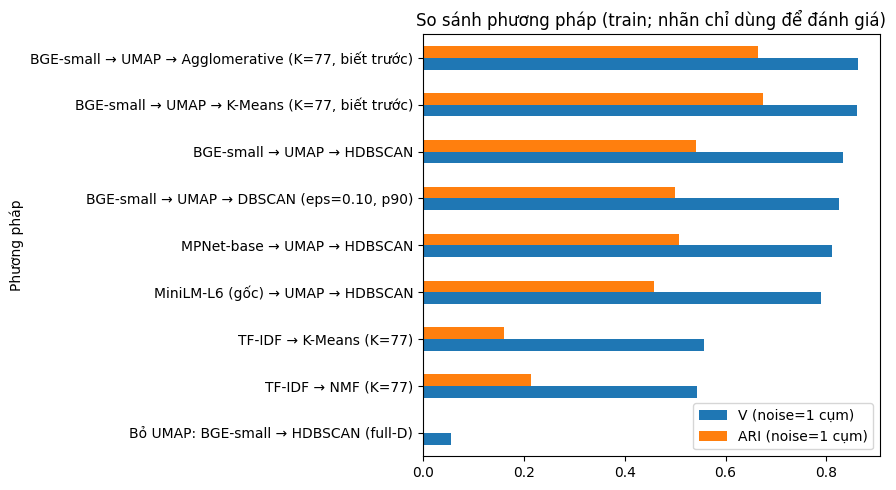

In [7]:
def run_benchmark(cfg, texts, y, encoders, include_no_umap=True):
    rows, preds, pipes = [], {}, {}
    for ename, path in encoders.items():
        X = embed(texts, path, 'train')
        p = TopicPipeline(Cfg(**{**asdict(cfg), 'encoder': path}))._fit_cluster(X)
        name = f'{ename} → UMAP → HDBSCAN'
        rows.append(evaluate_all(name, y, p.labels, X, p.clusterer)); preds[name] = p.labels; pipes[ename] = (p, X)
    base_name = list(encoders)[0]
    p, X = pipes[cfg_name] if (cfg_name := next((k for k, v in encoders.items() if v == cfg.encoder), base_name)) in pipes else pipes[base_name]
    Z = p.Z
    for name, pred in {f'{cfg_name} → UMAP → K-Means (K={K_TRUE}, biết trước)': KMeans(K_TRUE, n_init=5, random_state=cfg.seed).fit_predict(Z),
                       f'{cfg_name} → UMAP → Agglomerative (K={K_TRUE}, biết trước)': AgglomerativeClustering(K_TRUE, linkage='ward').fit_predict(Z)}.items():
        rows.append(evaluate_all(name, y, pred, X)); preds[name] = pred
    # DBSCAN: eps theo k-distance (phân vị 90), KHÔNG dùng nhãn
    d = NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1]
    from sklearn.cluster import DBSCAN
    eps = float(np.percentile(d, 90)); pr = DBSCAN(eps=eps, min_samples=10).fit_predict(Z)
    name = f'{cfg_name} → UMAP → DBSCAN (eps={eps:.2f}, p90)'; rows.append(evaluate_all(name, y, pr, X)); preds[name] = pr
    if include_no_umap:
        h = hdbscan.HDBSCAN(min_cluster_size=cfg.min_cluster_size, min_samples=cfg.min_samples,
                            algorithm='generic').fit(X.astype(np.float64))
        name = f'Bỏ UMAP: {cfg_name} → HDBSCAN (full-D)'; rows.append(evaluate_all(name, y, h.labels_, X)); preds[name] = h.labels_
    # Không dùng embedding
    tf = TfidfVectorizer(stop_words='english', min_df=3, ngram_range=(1, 2)).fit_transform(texts)
    from sklearn.decomposition import NMF
    for name, pred in {f'TF-IDF → K-Means (K={K_TRUE})': KMeans(K_TRUE, n_init=3, random_state=cfg.seed).fit_predict(tf),
                       f'TF-IDF → NMF (K={K_TRUE})': NMF(K_TRUE, init='nndsvda', max_iter=300, random_state=cfg.seed).fit_transform(tf).argmax(1)}.items():
        rows.append(evaluate_all(name, y, pred)); preds[name] = pred
    return pd.DataFrame(rows).set_index('Phương pháp'), preds

bench, bench_preds = run_benchmark(CFG, train.clean.values, y_tr, BENCH_ENCODERS, INCLUDE_NO_UMAP)
cols = ['Số cụm', 'Noise', 'V (noise=1 cụm)', 'V (noise=singleton)', 'V (bỏ noise)', 'Coverage',
        'ARI (noise=1 cụm)', 'ARI (bỏ noise)', 'Purity (trọng số)', 'Intent có cụm riêng', 'Silhouette (cosine)', 'DBCV']
display(bench[cols].sort_values('V (noise=1 cụm)', ascending=False).round(3))

ax = bench[['V (noise=1 cụm)', 'ARI (noise=1 cụm)']].sort_values('V (noise=1 cụm)').plot.barh(figsize=(9, 5))
ax.set_title('So sánh phương pháp (train; nhãn chỉ dùng để đánh giá)'); plt.tight_layout(); plt.show()

### 5b. Chênh lệch có thật không? (paired bootstrap)

So cặp quan trọng: encoder mới vs encoder gốc, và HDBSCAN vs K-Means có K biết trước.

In [8]:
names = list(bench_preds)
hdb_names = [n for n in names if n.endswith('→ UMAP → HDBSCAN')]
km_name = next(n for n in names if 'K-Means (K=' in n and 'TF-IDF' not in n)
pairs = [(hdb_names[1] if len(hdb_names) > 1 else hdb_names[0], hdb_names[0]), (hdb_names[0], km_name)]
for a, b in pairs:
    print(f'{a}  -  {b}\n   ', paired_bootstrap(y_tr, bench_preds[a], bench_preds[b]))

BGE-small → UMAP → HDBSCAN  -  MiniLM-L6 (gốc) → UMAP → HDBSCAN
    {'diff': 0.04314667771842522, 'CI95': (np.float64(0.0396), np.float64(0.0479)), 'khác biệt thật': True}
MiniLM-L6 (gốc) → UMAP → HDBSCAN  -  BGE-small → UMAP → K-Means (K=77, biết trước)
    {'diff': -0.07027647302183103, 'CI95': (np.float64(-0.0744), np.float64(-0.0664)), 'khác biệt thật': True}


## 6. Độ ổn định (UMAP ngẫu nhiên)

Hai thước đo: (1) dao động metric theo seed (mean ± std); (2) **ARI giữa các lần chạy** – không cần nhãn, cho biết cùng dữ liệu nhưng seed khác thì cụm có giống nhau không. Số cụm "77" có thể chỉ là trùng hợp nếu dao động 74–78.

In [9]:
def stability(X, y, cfg, seeds):
    runs, rows = [], []
    for s in seeds:
        p = TopicPipeline(Cfg(**{**asdict(cfg), 'seed': s}))._fit_cluster(X)
        runs.append(p.labels); rows.append(evaluate_all(f'seed={s}', y, p.labels, X, p.clusterer))
    tab = pd.DataFrame(rows).set_index('Phương pháp')
    pair = []
    for i, j in itertools.combinations(range(len(runs)), 2):
        m = (runs[i] != -1) & (runs[j] != -1); pair.append(ARI(runs[i][m], runs[j][m]))
    return tab, float(np.mean(pair)), float(np.std(pair))

stab, pair_mean, pair_std = stability(X_tr, y_tr, CFG, range(CFG.n_seeds))
keep = ['Số cụm', 'Noise', 'V (noise=1 cụm)', 'ARI (bỏ noise)', 'DBCV']
display(stab[keep].round(3)); display(stab[keep].agg(['mean', 'std']).round(3))
print(f'ARI giữa các lần chạy (không dùng nhãn): {pair_mean:.3f} ± {pair_std:.3f}')

,Số cụm,Noise,V (noise=1 cụm),ARI (bỏ noise),DBCV
Phương pháp,,,,,
seed=0,79,0.080,0.831,0.684,0.416
seed=1,77,0.082,0.829,0.672,0.385
seed=2,82,0.086,0.824,0.689,0.430
seed=3,75,0.080,0.828,0.672,0.445
seed=4,79,0.096,0.824,0.693,0.337


,Số cụm,Noise,V (noise=1 cụm),ARI (bỏ noise),DBCV
mean,78.400,0.085,0.827,0.682,0.403
std,2.608,0.007,0.003,0.010,0.043


ARI giữa các lần chạy (không dùng nhãn): 0.958 ± 0.016


## 7. Quét tham số + kiểm tra metric không cần nhãn

Khi triển khai thật sẽ **không có nhãn** để chọn `min_cluster_size`. Nếu DBCV tương quan mạnh với V thật thì có thể chọn tham số bằng DBCV – kiểm tra ngay ở đây thay vì giả định.

In [10]:
rows = []
for mcs, sel in itertools.product((20, 30, 50, 80), ('eom', 'leaf')):
    cl = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=CFG.min_samples, cluster_selection_method=sel,
                         gen_min_span_tree=True).fit(pipe.Z)
    rows.append(evaluate_all(f'mcs={mcs}, {sel}', y_tr, cl.labels_, X_tr, cl))
sweep = pd.DataFrame(rows).set_index('Phương pháp')
display(sweep[['Số cụm', 'Noise', 'V (noise=1 cụm)', 'V (noise=singleton)', 'ARI (bỏ noise)', 'DBCV', 'Silhouette (cosine)']].round(3))

for internal in ('DBCV', 'Silhouette (cosine)'):
    s = sweep[[internal, 'V (noise=singleton)']].dropna()
    rho = spearmanr(s[internal], s['V (noise=singleton)'])[0] if len(s) > 2 else np.nan
    print(f'Spearman({internal}, V noise=singleton) = {rho:.2f}  ->',
          'có thể dùng để chọn tham số khi không có nhãn' if rho >= 0.7 else 'KHÔNG đủ tin cậy để thay nhãn')

,Số cụm,Noise,V (noise=1 cụm),V (noise=singleton),ARI (bỏ noise),DBCV,Silhouette (cosine)
Phương pháp,,,,,,,
"mcs=20, eom",184,0.081,0.806,0.824,0.570,0.313,0.228
"mcs=20, leaf",204,0.139,0.772,0.801,0.532,0.264,0.234
"mcs=30, eom",125,0.095,0.814,0.832,0.658,0.315,0.225
"mcs=30, leaf",134,0.122,0.794,0.818,0.624,0.299,0.220
"mcs=50, eom",75,0.074,0.833,0.841,0.673,0.432,0.222
"mcs=50, leaf",86,0.130,0.814,0.831,0.739,0.366,0.229
"mcs=80, eom",58,0.078,0.832,0.835,0.646,0.411,0.214
"mcs=80, leaf",62,0.120,0.822,0.833,0.717,0.362,0.217


Spearman(DBCV, V noise=singleton) = 0.93  -> có thể dùng để chọn tham số khi không có nhãn
Spearman(Silhouette (cosine), V noise=singleton) = -0.62  -> KHÔNG đủ tin cậy để thay nhãn


## 8. Kiểm định luận điểm "noise = emerging topic"

Giả lập: **giấu `n_hidden` intent** khi fit (coi là topic mới xuất hiện sau). Điểm "mới" = các câu của intent bị giấu (train + test, đều chưa được fit); điểm đối chứng = **test của các intent đã biết** (cũng chưa được fit, nên không bị thiên vị như khi giữ lại 20% train).

So sánh 3 detector trên cùng dữ liệu:

- **Noise flag**: câu bị HDBSCAN gắn `-1` (cách của pipeline gốc).
- **1 - strength**: độ yếu của việc thuộc cụm (liên tục).
- **kNN cosine distance**: khoảng cách trung bình tới k láng giềng gần nhất trong tập đã biết.

Chỉ số: **AUROC** (không phụ thuộc ngưỡng; 0.5 = ngẫu nhiên), **Recall**, **FPR** (tỉ lệ câu đã biết bị gắn cờ oan), **Lift = Recall / FPR** (1.0 = ngẫu nhiên), **Precision so với base rate** (tỉ lệ câu mới trong tập đang xét). Với detector liên tục, ngưỡng đặt sao cho FPR ≈ 10%.

Bước **khám phá**: gom riêng các câu bị gắn cờ (UMAP + HDBSCAN nhỏ) và đếm có bao nhiêu intent bị giấu được **khôi phục thành cụm thuần ≥ 60%**. Đây mới là điều "phát hiện emerging topic" thực sự cần.

In [11]:
def discover(Xf, yf, hidden, cfg):
    if len(Xf) < 3 * cfg.emerge_mcs: return 0
    Zf = umap.UMAP(n_neighbors=min(15, len(Xf) - 1), n_components=5, min_dist=0.0, metric='cosine',
                   random_state=cfg.seed).fit_transform(Xf)
    lab = hdbscan.HDBSCAN(min_cluster_size=cfg.emerge_mcs, min_samples=3).fit_predict(Zf)
    found = set()
    for c in set(lab) - {-1}:
        v, n = np.unique(yf[lab == c], return_counts=True)
        if n.max() / n.sum() >= 0.6 and v[n.argmax()] in hidden: found.add(v[n.argmax()])
    return len(found)

def emerging_experiment(cfg, X_tr, y_tr, X_te, y_te, n_hidden=5, trials=3, seed=0):
    rng = np.random.RandomState(seed); intents = np.unique(y_tr); rows = []
    for t in range(trials):
        held = rng.choice(intents, n_hidden, replace=False); keep = ~np.isin(y_tr, held)
        p = TopicPipeline(cfg).fit(X_tr[keep], None, keywords=False)
        te_new = np.isin(y_te, held)
        Xn = np.vstack([X_tr[~keep], X_te[te_new]]); yn = np.r_[y_tr[~keep], y_te[te_new]]
        Xc, yc = X_te[~te_new], y_te[~te_new]
        rn, rc = p.predict(Xn), p.predict(Xc)
        dets = {'HDBSCAN noise flag': (rn.noise.values.astype(float), rc.noise.values.astype(float), True),
                'HDBSCAN 1-strength': (1 - rn.strength.values, 1 - rc.strength.values, False),
                'kNN cosine distance': (rn.novelty.values, rc.novelty.values, False)}
        for name, (sn, sc, binary) in dets.items():
            auc = roc_auc_score(np.r_[np.ones(len(sn)), np.zeros(len(sc))], np.r_[sn, sc])
            thr = 0.5 if binary else np.percentile(sc, 90)
            fn, fc = sn >= thr, sc >= thr
            rec, fpr = fn.mean(), fc.mean(); base = len(sn) / (len(sn) + len(sc))
            prec = fn.sum() / max(fn.sum() + fc.sum(), 1)
            found = discover(np.vstack([Xn[fn], Xc[fc]]), np.r_[yn[fn], yc[fc]], set(held), cfg)
            rows.append({'Detector': name, 'AUROC': auc, 'Recall': rec, 'FPR': fpr, 'Lift (R/FPR)': rec / max(fpr, 1e-9),
                         'Precision': prec, 'Base rate': base, 'Precision/Base': prec / base,
                         'Intent mới khôi phục': found / n_hidden})
    return pd.DataFrame(rows)

emerg = emerging_experiment(CFG, X_tr, y_tr, X_te, y_te)
emerg_summary = emerg.groupby('Detector').mean(numeric_only=True)
display(emerg_summary.round(3))

,AUROC,Recall,FPR,Lift (R/FPR),Precision,Base rate,Precision/Base,Intent mới khôi phục
Detector,,,,,,,,
HDBSCAN 1-strength,0.644,0.203,0.105,1.942,0.368,0.233,1.572,0.800
HDBSCAN noise flag,0.539,0.176,0.097,1.821,0.355,0.233,1.515,0.733
kNN cosine distance,0.864,0.552,0.100,5.514,0.621,0.233,2.666,1.000


## 9. Chất lượng keyword (c-TF-IDF cũ vs mới)

Đo bằng 4 số: **từ nhiễu** (didn, hasn, ...), **n-gram lặp token** (`pin pin`), **đa dạng** (tỉ lệ từ khác nhau giữa các topic; thấp = nhiều topic dùng chung từ), và **NPMI coherence** (các từ khoá có thật sự đồng xuất hiện trong câu không; càng cao càng gắn kết).

In [12]:
def top_keywords_original(texts, topics, n=8):
    # Bản gốc: ghép mọi câu của cụm bằng dấu cách -> bigram vắt qua ranh giới câu.
    topics = np.asarray(topics); ids = sorted(set(topics) - {-1}); texts = np.asarray(texts)
    docs = [' '.join(texts[topics == t]) for t in ids]
    cv = CountVectorizer(stop_words='english', ngram_range=(1, 2)); c = cv.fit_transform(docs).toarray().astype(float)
    tf = c / c.sum(1, keepdims=True); idf = np.log(1 + c.sum() / len(ids) / c.sum(0)); w = cv.get_feature_names_out()
    return {t: ', '.join(w[np.argsort(-(tf[i] * idf))[:n]]) for i, t in enumerate(ids)}

def npmi_coherence(texts, kw, n=8):
    uni = sorted({w for s in kw.values() for w in s.split(', ') if ' ' not in w})
    B = CountVectorizer(vocabulary=uni, binary=True, token_pattern=r'(?u)\b[a-zA-Z]{2,}\b').transform(texts).tocsc()
    N, idx, P = B.shape[0], {w: i for i, w in enumerate(uni)}, np.asarray(B.sum(0)).ravel() / B.shape[0]
    scores = []
    for s in kw.values():
        ws = [w for w in s.split(', ') if ' ' not in w][:n]
        if len(ws) < 3: continue
        v = []
        for a, b in itertools.combinations(ws, 2):
            pij = B[:, idx[a]].multiply(B[:, idx[b]]).sum() / N
            v.append(-1.0 if pij == 0 else (1.0 if pij >= 1 else np.log(pij / (P[idx[a]] * P[idx[b]])) / -np.log(pij)))
        scores.append(np.mean(v))
    return float(np.mean(scores)) if scores else np.nan

def keyword_quality(kw, texts):
    toks = [w for s in kw.values() for w in re.findall('[a-z]+', s)]
    uni = [w for s in kw.values() for w in s.split(', ') if ' ' not in w]
    return {'Từ nhiễu': sum(w in EXTRA_STOP for w in toks),
            'N-gram lặp token': sum(any(len(set(w.split())) < len(w.split()) for w in s.split(', ')) for s in kw.values()),
            'Đa dạng (unigram)': len(set(uni)) / max(len(uni), 1), 'NPMI coherence': npmi_coherence(texts, kw)}

kw_old = top_keywords_original(train.clean.values, pipe.labels)
kw_new = pipe.keywords
display(pd.DataFrame({'Gốc': keyword_quality(kw_old, train.clean.values),
                      'Mới (per-sentence + support)': keyword_quality(kw_new, train.clean.values)}).round(3))
sample = sorted(kw_new)[:8]
pd.set_option('display.max_colwidth', 80)
display(pd.DataFrame({'topic': sample, 'gốc': [kw_old[t] for t in sample], 'mới': [kw_new[t] for t in sample]}))

,Gốc,Mới (per-sentence + support)
Từ nhiễu,35.000,0.000
N-gram lặp token,5.000,0.000
Đa dạng (unigram),0.663,0.786
NPMI coherence,0.102,-0.009


,topic,gốc,mới
0,0,"details, change, address, personal, need change, personal details, edit, cha...","details, address, change, personal, personal details, edit, change address, ..."
1,1,"open, open account, age, daughter, children, account daughter, old, age limit","open, open account, age, daughter, children, old, age limit, kids"
2,2,"identity, verify, verify identity, verification, identity verification, id, ...","identity, verify identity, verify, verification, identity verification, iden..."
3,3,"code, verification code, verify, verification, verify card, need verify, cod...","verification code, code, verification, verify, verify card, verifying, code ..."
4,4,"change pin, change, pin, pin change, new pin, pin want, cash machines, need ...","change pin, change, pin, new pin, cash machines, machines, spain, vacation"
5,5,"disposable cards, disposable, cards, restrictions, restrictions disposable, ...","disposable cards, disposable, restrictions, restrictions disposable, cards, ..."
6,6,"delete, delete account, close, close account, account, account delete, servi...","delete, delete account, close, close account, service, company, terminate, t..."
7,7,"pin, unblock, blocked, unblock pin, pin times, wrong pin, times, entered","unblock, pin, blocked, unblock pin, pin times, wrong pin, entered, pin blocked"


## 10. Bảng topic (có kiểm tra bằng nhãn) và xử lý noise

- **Bảng topic**: `majority_label` và `purity` chỉ để kiểm tra. Cụm có purity thấp thường là cụm bị gộp nhiều intent.
- **Noise triage**: thay vì đổ nguyên ~10% noise vào một file, **gom noise thành nhóm ứng viên** và xếp theo `novelty`. Cột *Intent chiếm đa số* chỉ để chẩn đoán: nếu noise phần lớn là một vài intent gần nghĩa thì đó là **câu nằm ở biên giữa các topic đã biết**, không phải topic mới.

In [13]:
rows = []
for t, kw in pipe.keywords.items():
    sub = train[pipe.labels == t]; vc = sub.label_text.value_counts()
    rows.append({'topic': t, 'size': len(sub), 'keywords': kw, 'majority_label': vc.index[0],
                 'purity': round(vc.iloc[0] / len(sub), 2)})
topics = pd.DataFrame(rows).sort_values('size', ascending=False).reset_index(drop=True)
display(topics.head(10))
print(f"Cụm purity < 0.6: {(topics.purity < 0.6).sum()}/{len(topics)} | intent là majority của >=1 cụm: {topics.majority_label.nunique()}/{K_TRUE}")

# ----- Noise triage -----
noise_tr, noise_te = pipe.labels == -1, res_te.topic.values == -1
nz = np.vstack([pipe.Z[noise_tr], Z_te[noise_te]])
ntext = np.r_[train.clean.values[noise_tr], test.clean.values[noise_te]]
nlab = np.r_[train.label_text.values[noise_tr], test.label_text.values[noise_te]]
nsplit = np.r_[['train'] * noise_tr.sum(), ['test'] * noise_te.sum()]
nnov = np.r_[pipe.train_novelty[noise_tr], res_te.novelty.values[noise_te]]

grp = hdbscan.HDBSCAN(min_cluster_size=CFG.noise_mcs, min_samples=3).fit_predict(nz)
gkw = c_tfidf_keywords(ntext, grp, 6, max_df=0.5, min_support=0.1) if len(set(grp) - {-1}) > 1 else {}
cand = []
for g in sorted(set(grp) - {-1}):
    m = grp == g; vc = pd.Series(nlab[m]).value_counts()
    cand.append({'nhóm': g, 'size': int(m.sum()), 'novelty TB': round(nnov[m].mean(), 3), 'keywords': gkw.get(g, ''),
                 'Intent chiếm đa số (chẩn đoán)': vc.index[0], 'tỉ lệ': round(vc.iloc[0] / m.sum(), 2)})
cand = pd.DataFrame(cand).sort_values('novelty TB', ascending=False) if cand else pd.DataFrame()
display(cand.head(10))
top5 = pd.Series(nlab).value_counts(normalize=True).head(5).sum()
print(f'{len(nlab)} câu noise | {len(set(grp) - {-1})} nhóm ứng viên | noise còn rời rạc: {(grp == -1).mean():.0%} '
      f'| noise trải trên {len(set(nlab))} intent, 5 intent đầu chiếm {top5:.0%}')

noise_review = pd.DataFrame({'split': nsplit, 'text': ntext, 'novelty': nnov, 'candidate_group': grp, 'label_text': nlab}) \
                 .sort_values('novelty', ascending=False)

,topic,size,keywords,majority_label,purity
0,40,403,"extra, fee, extra fee, charged, pound, statement, charge, charged extra",card_payment_fee_charged,0.45
1,34,353,"currencies, gbp, salary, currency, fiat, fiat currencies, usd, hold",fiat_currency_support,0.36
2,2,330,"identity, verify identity, verify, verification, identity verification, iden...",why_verify_identity,0.36
3,65,250,"balance, deposited, deposit, cheque, cash deposit, updated, balance updated,...",balance_not_updated_after_cheque_or_cash_deposit,0.71
4,39,206,"failed, transfer failed, transfer, error, make transfer, error message, mess...",failed_transfer,0.57
5,37,206,"refund, requested refund, requested, refund statement, statement, refund sho...",Refund_not_showing_up,0.76
6,46,193,"topping, european, topping card, european bank, bank card, bank transfer, fe...",top_up_by_card_charge,0.44
7,30,189,"withdrawing, withdrawals, charged, fee, fee cash, withdrawal, free, cash wit...",cash_withdrawal_charge,0.90
8,41,178,"twice, charged twice, duplicate, double, charged, remove, double charged, re...",transaction_charged_twice,0.97
9,32,171,"fee transfer, fee, transferring, transferring money, free, transfers free, t...",transfer_fee_charged,0.74


Cụm purity < 0.6: 16/75 | intent là majority của >=1 cụm: 67/77


,nhóm,size,novelty TB,keywords,Intent chiếm đa số (chẩn đoán),tỉ lệ
9,9,11,0.153,deposit,receiving_money,0.55
19,19,14,0.146,"gas, cash, atm",wrong_amount_of_cash_received,0.36
13,13,15,0.137,"landlord, rent, new landlord, new, checked, double",transfer_not_received_by_recipient,1.00
20,20,9,0.136,"statement, make, payment, did",card_payment_not_recognised,0.44
34,34,8,0.132,"wallet, withdrawal, urgent, stolen, lost wallet, hours",cash_withdrawal_not_recognised,0.88
35,35,44,0.129,"freeze, freeze card, using, charges, town, used",card_payment_not_recognised,0.36
16,16,68,0.121,"contactless, work, contactless payments, payments, working, use",contactless_not_working,0.91
12,12,10,0.111,"tomorrow, rent, wrong account, right account, needs, payment wrong",cancel_transfer,1.00
27,27,30,0.110,"delivered, date, specific, certain, choose, certain date",card_delivery_estimate,1.00
4,4,15,0.106,"pounds, russian, ruble, russian ruble, ruble pounds, changed",card_payment_wrong_exchange_rate,0.93


1037 câu noise | 36 nhóm ứng viên | noise còn rời rạc: 8% | noise trải trên 54 intent, 5 intent đầu chiếm 39%


## 10b. Module Khai phá Mẫu (Pattern Mining Module)

Khám phá sâu cấu trúc ngữ nghĩa và hình học của từng cụm (cluster) thông qua 3 loại mẫu đặc trưng:
1. **Structural Query Pattern (Mẫu cấu trúc câu hỏi):** Phân tích n-gram khởi đầu câu (2-gram, 3-gram) và từ để hỏi (*wh-words / auxiliary verbs*) nhằm nhận diện hành vi đặt câu hỏi đặc trưng của khách hàng trong từng cụm.
2. **Sub-topic / Attribute Co-occurrence Pattern (Mẫu đồng xuất hiện thuộc tính):** Kết hợp chỉ số **Lift** (tần suất xuất hiện cục bộ so với toàn cục: $P(w|C) / P(w)$) và kiểm định $\chi^2$ (**Chi-square**) để trích xuất các thực thể, trạng từ chỉ thời gian/hành động hoặc thuộc tính phụ trợ đặc trưng nhất đi kèm với chủ đề chính.
3. **Cluster Boundary / Confusion Pattern (Mẫu chồng lấn ranh giới cụm):** Đo lường tỷ lệ láng giềng khác cụm (**kNN Cross-cluster Overlap** trong không gian UMAP 5D) kết hợp khoảng cách tâm cụm (trên cả UMAP 5D và BGE 384D) để chỉ ra chính xác cụm nào đang nằm sát biên hoặc đan xen mạnh nhất với cụm nào, giải thích trực tiếp nguyên nhân làm giảm chỉ số Purity.

=== BẢNG TỔNG HỢP KHAI PHÁ MẪU ĐẶC TRƯNG CHO TỪNG CỤM (TOP 15 CỤM LỚN NHẤT) ===


Topic ID,Keywords chính,Mẫu câu hỏi phổ biến (Structural Pattern),Thuộc tính đặc trưng (Co-occurrence Pattern),Cụm dễ nhầm lẫn nhất (Boundary Pattern),Size,Purity
19,"extra, fee, extra fee, charged, pound, statement, charged extra, fee statement","[WHY: 24%] ""why was..."" (6%)","extra (35%, lift 13.8x), pound (10%, lift 22.4x), extra fee (15%, lift 15.2x), charged (40%, lift 7.8x), charge (26%, lift 8.7x)","Topic 20 [twice, charged twice] (Cận biên: d_UMAP=1.82, d_Cos=0.07, chồng lấn kNN: 0.0%)",404,0.45
46,"currencies, gbp, salary, fiat, currency, fiat currencies, usd, hold","[WHAT: 23%] ""can i..."" (11%)","currencies (46%, lift 22.3x), gbp (19%, lift 28.2x), salary (11%, lift 27.5x), currency (23%, lift 11.7x), exchange (27%, lift 5.1x)","Topic 23 [exchanging, currency] (Cận biên: d_UMAP=1.78, d_Cos=0.08, chồng lấn kNN: 0.0%)",354,0.36
2,"identity, verify identity, verify, identity verification, verification, identity check, use account, prove","[WHAT: 23%] ""why do..."" (7%)","identity (66%, lift 30.0x), verify identity (18%, lift 30.3x), verify (26%, lift 16.8x), identity verification (11%, lift 30.3x), check (11%, lift 5.7x)","Topic 5 [verification code, code] (Cận biên: d_UMAP=3.21, d_Cos=0.18, chồng lấn kNN: 0.0%)",330,0.36
71,"balance, deposited, deposit, cheque, cash deposit, updated, balance updated, deposit account","[WHY: 15%] ""i deposited..."" (9%)","deposit (28%, lift 28.6x), cheque (24%, lift 23.2x), updated (12%, lift 35.3x), cash (36%, lift 5.3x), check (14%, lift 7.7x)","Topic 62 [transferred, recipient] (Cận biên: d_UMAP=1.18, d_Cos=0.07, chồng lấn kNN: 0.3%)",251,0.71
61,"failed, transfer failed, transfer, error, make transfer, error message, message, transfer account","[WHY: 23%] ""i tried..."" (6%), ""my transfer..."" (6%)","transfer failed (11%, lift 46.4x), make transfer (10%, lift 28.5x), error (11%, lift 17.8x), transfer account (10%, lift 16.4x), tried (21%, lift 8.8x)","Topic 38 [transfer declined, declined] (Cận biên: d_UMAP=1.16, d_Cos=0.06, chồng lấn kNN: 0.3%)",206,0.57
50,"topping, european, topping card, european bank, bank card, bank transfer, credit card, fee topping","[WHAT: 20%] ""is there..."" (9%), ""how do i..."" (7%), ""how much..."" (6%)","card top (10%, lift 31.7x), top (74%, lift 7.1x), top account (13%, lift 19.0x), top card (15%, lift 15.8x), bank (18%, lift 10.5x)","Topic 49 [limit, ups] (Cận biên: d_UMAP=1.05, d_Cos=0.08, chồng lấn kNN: 0.0%)",193,0.44
28,"withdrawing, withdrawals, fee, charged, withdrawal, fee cash, free, cash","[WHY: 34%] ""why was..."" (10%), ""why am i..."" (7%), ""why did..."" (7%)","fee (47%, lift 10.7x), charged (51%, lift 10.0x), cash (52%, lift 7.6x), withdrawal (28%, lift 10.1x), free (11%, lift 18.1x)","Topic 27 [atms, home] (Cận biên: d_UMAP=2.63, d_Cos=0.16, chồng lấn kNN: 0.0%)",190,0.91
20,"twice, charged twice, duplicate, double, charged, remove, double charged, restaurant","[WHY: 14%] ""i have..."" (14%), ""i was..."" (10%)","charged twice (27%, lift 57.1x), duplicate (15%, lift 49.5x), restaurant (9%, lift 37.2x), charged (48%, lift 9.4x), double (11%, lift 23.3x)","Topic 19 [extra, fee] (Cận biên: d_UMAP=1.82, d_Cos=0.07, chồng lấn kNN: 0.0%)",175,0.98
15,"fee transfer, fee, transferring, transferring money, transfers, free, transfers free, charged fee","[WHY: 25%] ""why was..."" (9%)","fee transfer (15%, lift 56.3x), transferring money (10%, lift 31.0x), transferring (12%, lift 25.6x), charged fee (15%, lift 15.7x), charged (40%, lift 7.8x)","Topic 19 [extra, fee] (Cận biên: d_UMAP=2.09, d_Cos=0.08, chồng lấn kNN: 0.0%)",171,0.74
43,"payment pending, pending, showing pending, pending payment, payment showing, payment card, card payment, showing","[WHY: 19%] ""why is..."" (10%), ""how long..."" (7%), ""my card..."" (7%)","pending (74%, lift 18.2x), payment pending (13%, lift 58.8x), payment still (12%, lift 56.0x), payment (84%, lift 11.9x), pending payment (9%, lift 55.1x)","Topic 42 [payment work, card payment] (Cận biên: d_UMAP=1.30, d_C


[+] Đã lưu toàn bộ 76 mẫu cụm vào file 'cluster_patterns_v3.csv'.


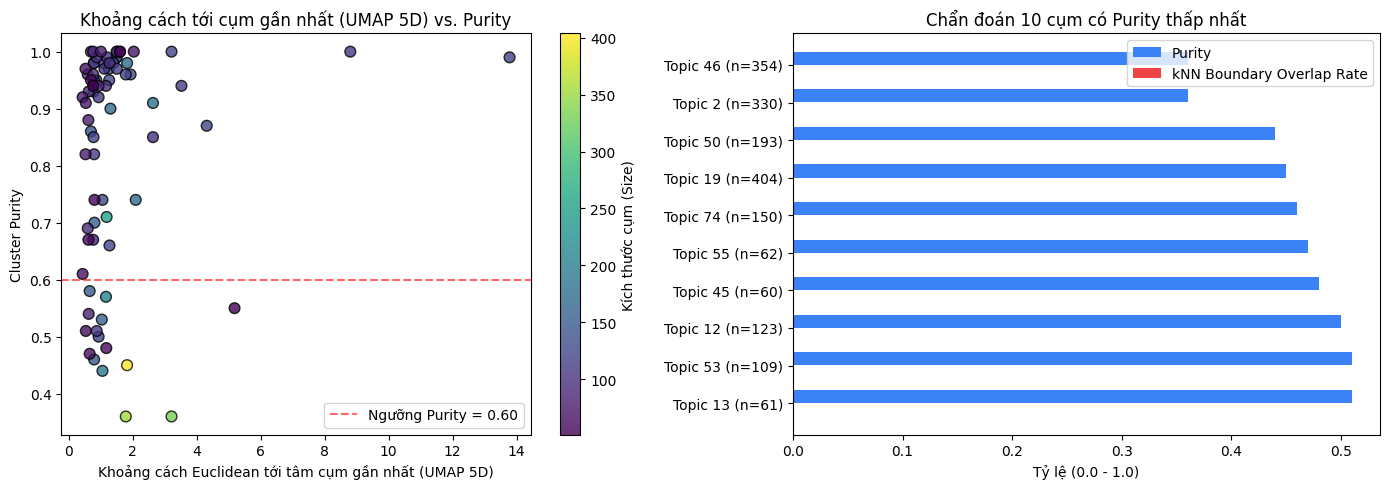

In [14]:
from collections import Counter
from sklearn.metrics.pairwise import euclidean_distances, cosine_distances

class ClusterPatternMiner:
    """
    Module khai phá mẫu đặc trưng cho từng cụm sau bước HDBSCAN.
    Tương thích trực tiếp với đối tượng `pipe` (TopicPipeline) và tập dữ liệu `train`.
    """
    def __init__(self, pipe, texts, X_emb, y_true_text=None):
        self.pipe = pipe
        self.texts = np.asarray(texts)
        self.labels = np.asarray(pipe.labels)
        self.Z = np.asarray(pipe.Z)          # Không gian UMAP 5D
        self.X = np.asarray(X_emb)           # Không gian BGE-small 384D
        self.y_true_text = np.asarray(y_true_text) if y_true_text is not None else None
        self.cluster_ids = sorted(set(self.labels) - {-1})
        
        # Tập từ để hỏi và trợ động từ đầu câu phổ biến trong giao dịch ngân hàng
        self.wh_words = {
            'how', 'what', 'why', 'can', 'is', 'do', 'does', 'where', 'when', 
            'who', 'which', 'could', 'would', 'should', 'will', 'are', 'did', 
            'was', 'were', 'have', 'has', 'may', 'might'
        }

    # -------------------------------------------------------------------------
    # 1. STRUCTURAL QUERY PATTERN (Mẫu cấu trúc câu hỏi đầu câu)
    # -------------------------------------------------------------------------
    def mine_structural_patterns(self, top_k=3, min_ratio=0.06):
        structural_patterns = {}
        
        for cid in self.cluster_ids:
            c_texts = self.texts[self.labels == cid]
            n_docs = len(c_texts)
            prefix_counts = Counter()
            wh_counts = Counter()
            
            for t in c_texts:
                # Tách từ giữ lại cấu trúc đầu câu (bao gồm cả stop words như how, do, i...)
                tokens = re.findall(r'\b[a-zA-Z]+\b', t.lower())
                if not tokens:
                    continue
                
                # Thống kê từ để hỏi ở vị trí đầu tiên
                if tokens[0] in self.wh_words:
                    wh_counts[tokens[0]] += 1
                
                # Bắt cụm 3-gram và 2-gram ở vị trí đầu câu
                if len(tokens) >= 3:
                    prefix_counts[' '.join(tokens[:3])] += 1
                if len(tokens) >= 2:
                    prefix_counts[' '.join(tokens[:2])] += 1
            
            # Ưu tiên lọc các 3-gram có độ phủ tốt, tránh trùng lặp với 2-gram con
            selected = []
            used_prefixes = set()
            
            for gram, count in prefix_counts.most_common(15):
                ratio = count / n_docs
                if ratio < min_ratio and len(selected) >= 1:
                    break
                # Kiểm tra tránh dư thừa (VD: đã có "how do i" thì bỏ qua "how do")
                if any(gram in u or u in gram for u in used_prefixes):
                    continue
                selected.append(f'"{gram}..." ({ratio:.0%})')
                used_prefixes.add(gram)
                if len(selected) >= top_k:
                    break
            
            # Thông tin bổ trợ về từ để hỏi chủ đạo
            top_wh = wh_counts.most_common(1)
            wh_str = f"[{top_wh[0][0].upper()}: {top_wh[0][1]/n_docs:.0%}] " if top_wh else ""
            
            structural_patterns[cid] = wh_str + (", ".join(selected) if selected else "Cấu trúc câu trần thuật đa dạng")
            
        return structural_patterns

    # -------------------------------------------------------------------------
    # 2. SUB-TOPIC / ATTRIBUTE CO-OCCURRENCE PATTERN (Lift & Chi-square)
    # -------------------------------------------------------------------------
    def mine_cooccurrence_patterns(self, top_k=5, min_cluster_support=0.08):
        # Loại bỏ các từ nối/đại từ cơ bản nhưng GIỮ LẠI các từ chỉ thời gian/trạng thái 
        # (như today, yesterday, ago, immediately, still, yet...) để bắt thuộc tính phụ trợ
        basic_stop = set(ENGLISH_STOP_WORDS) - {
            'not', 'no', 'never', 'nothing', 'none', 'empty', 'still', 'yet', 
            'already', 'again', 'back', 'twice', 'double', 'extra', 'top', 'up', 'down'
        }
        
        cv = CountVectorizer(
            stop_words=list(basic_stop), 
            ngram_range=(1, 2), 
            binary=True, 
            min_df=3,
            token_pattern=r'(?u)\b[a-zA-Z]{3,}\b'
        )
        X_bin = cv.fit_transform(self.texts).tocsr()
        vocab = cv.get_feature_names_out()
        
        N = len(self.texts)
        global_counts = np.asarray(X_bin.sum(axis=0)).ravel()
        p_global = global_counts / N  # Xác suất toàn cục P(w)
        
        cooc_patterns = {}
        
        for cid in self.cluster_ids:
            mask = (self.labels == cid)
            n_c = mask.sum()
            
            # Lấy tập từ khóa chính hiện tại của cụm để loại trừ (chỉ tìm thuộc tính phụ trợ/mở rộng)
            main_kws_raw = self.pipe.keywords.get(cid, "")
            main_kws_set = set( [w.strip() for w in main_kws_raw.split(',')] )
            
            # Tần suất trong cụm và ngoài cụm
            c_counts = np.asarray(X_bin[mask].sum(axis=0)).ravel()
            p_given_c = c_counts / n_c  # Xác suất có điều kiện P(w | Cluster)
            
            # Tính Lift = P(w | C) / P(w)
            lift = p_given_c / np.maximum(p_global, 1e-9)
            
            # Tính thống kê Chi-square (2x2 contingency table: A, B, C, D)
            A = c_counts.astype(float)
            B = (global_counts - c_counts).astype(float)
            C = (n_c - c_counts).astype(float)
            D = (N - n_c - B).astype(float)
            
            denom = (A + B) * (C + D) * (A + C) * (B + D)
            chi2 = np.where(denom > 0, N * ((A * D - B * C) ** 2) / denom, 0.0)
            
            # Điểm kết hợp: Ưu tiên các thuộc tính có Chi2 cao, đồng xuất hiện dương (A*D > B*C) 
            # và đạt ngưỡng support tối thiểu trong cụm
            valid_mask = (p_given_c >= min_cluster_support) & ((A * D) > (B * C)) & (c_counts >= 3)
            
            candidates = []
            for idx in np.where(valid_mask)[0]:
                term = vocab[idx]
                toks = term.split()
                if len(toks) == 2 and toks[0] == toks[1]:
                    continue
                # Đánh dấu nếu là thuộc tính mở rộng nằm ngoài top 3 từ khóa chính
                top3_main = set(list(main_kws_set)[:3])
                if term in top3_main:
                    continue
                
                # Sắp xếp theo điểm kết hợp giữa Chi-square và Lift
                score = chi2[idx] * np.log1p(lift[idx])
                candidates.append((score, term, p_given_c[idx], lift[idx]))
            
            candidates.sort(key=lambda x: -x[0])
            
            chosen = []
            for _, term, prob, l_val in candidates[:top_k]:
                chosen.append(f"{term} ({prob:.0%}, lift {l_val:.1f}x)")
                
            cooc_patterns[cid] = ", ".join(chosen) if chosen else "Không có thuộc tính phụ trợ đột biến"
            
        return cooc_patterns

    # -------------------------------------------------------------------------
    # 3. CLUSTER BOUNDARY / CONFUSION PATTERN (Chồng lấn ranh giới cụm)
    # -------------------------------------------------------------------------
    def mine_boundary_patterns(self, k_neighbors=15):
        # Chỉ xét các điểm không phải noise để đo ranh giới giữa các cụm hợp lệ
        valid_mask = (self.labels != -1)
        Z_valid = self.Z[valid_mask]
        X_valid = self.X[valid_mask]
        labels_valid = self.labels[valid_mask]
        
        # 1. Đo tỷ lệ láng giềng khác cụm (kNN Cross-Cluster Overlap) trên UMAP 5D
        nn = NearestNeighbors(n_neighbors=k_neighbors + 1, metric='euclidean').fit(Z_valid)
        _, indices = nn.kneighbors(Z_valid)
        neighbor_labels = labels_valid[indices[:, 1:]]  # Bỏ chính nó ở cột 0
        
        # 2. Tính tâm cụm (Centroids) trên UMAP 5D và BGE 384D
        umap_centroids = np.array([Z_valid[labels_valid == cid].mean(axis=0) for cid in self.cluster_ids])
        emb_centroids = np.array([X_valid[labels_valid == cid].mean(axis=0) for cid in self.cluster_ids])
        
        umap_dist_matrix = euclidean_distances(umap_centroids)
        emb_dist_matrix = cosine_distances(emb_centroids)
        
        boundary_patterns = {}
        confusion_metrics = {}
        
        for i, cid in enumerate(self.cluster_ids):
            c_idx = np.where(labels_valid == cid)[0]
            c_neighbors = neighbor_labels[c_idx].ravel()
            
            # Tỷ lệ láng giềng thuộc về các cụm khác (Boundary Overlap Rate)
            foreign_neighbors = c_neighbors[c_neighbors != cid]
            overlap_rate = len(foreign_neighbors) / len(c_neighbors) if len(c_neighbors) > 0 else 0.0
            
            # Tìm cụm láng giềng xâm lấn nhiều nhất theo kNN
            if len(foreign_neighbors) > 0:
                top_confused_cid, count = Counter(foreign_neighbors).most_common(1)[0]
                knn_conf_ratio = count / len(c_neighbors)
            else:
                top_confused_cid, knn_conf_ratio = None, 0.0
                
            # Tìm cụm có tâm gần nhất trong không gian UMAP 5D
            dists_umap = umap_dist_matrix[i].copy()
            dists_umap[i] = np.inf
            nearest_umap_idx = np.argmin(dists_umap)
            nearest_umap_cid = self.cluster_ids[nearest_umap_idx]
            min_umap_dist = dists_umap[nearest_umap_idx]
            
            # Khoảng cách Cosine tương ứng trên không gian gốc 384D tới cụm gần nhất
            target_cid = top_confused_cid if (top_confused_cid is not None and knn_conf_ratio >= 0.03) else nearest_umap_cid
            target_idx = self.cluster_ids.index(target_cid)
            cos_dist_384d = emb_dist_matrix[i, target_idx]
            
            # Lấy 2 từ khóa đầu của cụm bị chồng lấn để dễ đọc hiểu trong báo cáo
            target_kw = ", ".join(self.pipe.keywords.get(target_cid, "").split(", ")[:2])
            
            if top_confused_cid is not None and knn_conf_ratio >= 0.05:
                desc = (f"Topic {target_cid} [{target_kw}] "
                        f"(Chồng lấn biên: {knn_conf_ratio:.1%} kNN, d_UMAP={dists_umap[target_idx]:.2f}, d_Cos={cos_dist_384d:.2f})")
            else:
                desc = (f"Topic {nearest_umap_cid} [{target_kw}] "
                        f"(Cận biên: d_UMAP={min_umap_dist:.2f}, d_Cos={cos_dist_384d:.2f}, chồng lấn kNN: {overlap_rate:.1%})")
                
            boundary_patterns[cid] = desc
            confusion_metrics[cid] = {
                'overlap_rate': overlap_rate,
                'min_umap_dist': min_umap_dist,
                'nearest_topic': target_cid
            }
            
        return boundary_patterns, umap_dist_matrix, confusion_metrics

    # -------------------------------------------------------------------------
    # 4. TỔNG HỢP BẢNG BÁO CÁO (DATAFRAME)
    # -------------------------------------------------------------------------
    def generate_report(self, topics_df=None):
        struct_pat = self.mine_structural_patterns()
        cooc_pat = self.mine_cooccurrence_patterns()
        bound_pat, umap_dist_mat, conf_metrics = self.mine_boundary_patterns()
        
        # Nếu có sẵn bảng `topics` từ Phần 10 thì ghép thêm Size và Purity để tiện đối chiếu
        purity_map, size_map, maj_map = {}, {}, {}
        if topics_df is not None:
            purity_map = dict(zip(topics_df['topic'], topics_df['purity']))
            size_map = dict(zip(topics_df['topic'], topics_df['size']))
            maj_map = dict(zip(topics_df['topic'], topics_df['majority_label']))
            
        report_rows = []
        for cid in self.cluster_ids:
            size = size_map.get(cid, int((self.labels == cid).sum()))
            row = {
                'Topic ID': cid,
                'Size': size,
                'Purity': purity_map.get(cid, np.nan),
                'Keywords chính': self.pipe.keywords.get(cid, ''),
                'Mẫu câu hỏi phổ biến (Structural Pattern)': struct_pat[cid],
                'Thuộc tính đặc trưng (Co-occurrence Pattern)': cooc_pat[cid],
                'Cụm dễ nhầm lẫn nhất (Boundary Pattern)': bound_pat[cid],
                '_overlap_rate': conf_metrics[cid]['overlap_rate'],
                '_min_umap_dist': conf_metrics[cid]['min_umap_dist']
            }
            if maj_map:
                row['Majority Intent (Chẩn đoán)'] = maj_map.get(cid, '')
            report_rows.append(row)
            
        df_report = pd.DataFrame(report_rows).sort_values('Size', ascending=False).reset_index(drop=True)
        return df_report, umap_dist_mat


# =============================================================================
# GẮN PHƯƠNG THỨC VÀO CLASS TopicPipeline VÀ THỰC THI
# =============================================================================
def _mine_patterns_method(self, texts, X_emb, topics_df=None):
    miner = ClusterPatternMiner(self, texts, X_emb)
    return miner.generate_report(topics_df=topics_df)

TopicPipeline.mine_patterns = _mine_patterns_method

# Chạy khai phá mẫu trên tập Train đã fit ở các phần trước
df_patterns_full, umap_dist_matrix = pipe.mine_patterns(train.clean.values, X_tr, topics_df=topics)

# Bảng chuẩn gồm đúng 5 cột chính theo yêu cầu để đưa vào Báo cáo Word (+ cột Size/Purity hỗ trợ phân tích)
report_cols = [
    'Topic ID', 
    'Keywords chính', 
    'Mẫu câu hỏi phổ biến (Structural Pattern)', 
    'Thuộc tính đặc trưng (Co-occurrence Pattern)', 
    'Cụm dễ nhầm lẫn nhất (Boundary Pattern)'
]

# Hiển thị 15 cụm lớn nhất
pd.set_option('display.max_colwidth', 120)
print("=== BẢNG TỔNG HỢP KHAI PHÁ MẪU ĐẶC TRƯNG CHO TỪNG CỤM (TOP 15 CỤM LỚN NHẤT) ===")
display(df_patterns_full[report_cols + ['Size', 'Purity']].head(15))

# Xuất file CSV chuẩn phục vụ đưa vào báo cáo Word
csv_filename = 'cluster_patterns_v3.csv'
df_patterns_full[report_cols + ['Size', 'Purity', 'Majority Intent (Chẩn đoán)']].to_csv(
    csv_filename, index=False, encoding='utf-8-sig'
)
print(f"\n[+] Đã lưu toàn bộ {len(df_patterns_full)} mẫu cụm vào file '{csv_filename}'.")

# =============================================================================
# TRỰC QUAN HÓA MỐI QUAN HỆ GIỮA CHỒNG LẤN RANH GIỚI (BOUNDARY) VÀ ĐỘ TINH KHIẾT (PURITY)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Tương quan giữa Khoảng cách tâm cụm gần nhất (UMAP) và Purity
sc = axes[0].scatter(
    df_patterns_full['_min_umap_dist'], 
    df_patterns_full['Purity'], 
    c=df_patterns_full['Size'], 
    cmap='viridis', alpha=0.8, edgecolors='k', s=60
)
axes[0].axhline(0.6, color='red', linestyle='--', alpha=0.6, label='Ngưỡng Purity = 0.60')
axes[0].set_title('Khoảng cách tới cụm gần nhất (UMAP 5D) vs. Purity')
axes[0].set_xlabel('Khoảng cách Euclidean tới tâm cụm gần nhất (UMAP 5D)')
axes[0].set_ylabel('Cluster Purity')
axes[0].legend()
plt.colorbar(sc, ax=axes[0], label='Kích thước cụm (Size)')

# Biểu đồ 2: Top 10 cụm có tỷ lệ chồng lấn biên ( hoặc khoảng cách tâm gần nhất) cao nhất và Purity tương ứng
low_purity_clusters = df_patterns_full.sort_values('Purity', ascending=True).head(10)
y_pos = np.arange(len(low_purity_clusters))
axes[1].barh(y_pos - 0.18, low_purity_clusters['Purity'], height=0.35, label='Purity', color='#3b82f6')
axes[1].barh(y_pos + 0.18, low_purity_clusters['_overlap_rate'], height=0.35, label='kNN Boundary Overlap Rate', color='#ef4444')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([f"Topic {t} (n={s})" for t, s in zip(low_purity_clusters['Topic ID'], low_purity_clusters['Size'])])
axes[1].set_xlabel('Tỷ lệ (0.0 - 1.0)')
axes[1].set_title('Chẩn đoán 10 cụm có Purity thấp nhất')
axes[1].legend()
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# Tự động tải file xuống nếu đang chạy trên Google Colab
pass


## 11. Kết luận tự động và lưu kết quả

Các câu kết luận bên dưới được **sinh từ số đo vừa tính**, không phải văn bản cố định, nên sẽ đổi theo dữ liệu/tham số của bạn.

In [16]:
def verdict():
    L = []
    h = [n for n in bench.index if n.endswith('→ UMAP → HDBSCAN')]
    if len(h) > 1:
        a, b = bench.loc[h[1], 'V (noise=1 cụm)'], bench.loc[h[0], 'V (noise=1 cụm)']
        bs = paired_bootstrap(y_tr, bench_preds[h[1]], bench_preds[h[0]])
        L.append(f"Encoder: {h[1]} V={a:.3f} vs {h[0]} V={b:.3f} (bootstrap {bs['CI95']}, "
                 f"{'khác biệt thật' if bs['khác biệt thật'] else 'chưa đủ bằng chứng'}).")
    km = next((n for n in bench.index if 'K-Means (K=' in n and 'TF-IDF' not in n), None)
    if km and h:
        L.append(f"HDBSCAN (không biết K) V={bench.loc[h[0],'V (noise=1 cụm)']:.3f} so với K-Means (biết K) V={bench.loc[km,'V (noise=1 cụm)']:.3f}: "
                 f"{'HDBSCAN thua về độ chính xác, giá trị nằm ở việc không cần K' if bench.loc[km,'V (noise=1 cụm)'] > bench.loc[h[0],'V (noise=1 cụm)'] else 'HDBSCAN ngang hoặc hơn'}.")
    L.append(f"Tổng quát hoá: V Train {row_tr['V (noise=1 cụm)']:.3f} -> Test {row_te['V (noise=1 cụm)']:.3f}.")
    L.append(f"Ổn định: ARI giữa các seed = {pair_mean:.2f}; số cụm {stab['Số cụm'].min()}–{stab['Số cụm'].max()}.")
    nf, kn = emerg_summary.loc['HDBSCAN noise flag'], emerg_summary.loc['kNN cosine distance']
    L.append(f"Emerging topic: noise flag lift={nf['Lift (R/FPR)']:.2f}, AUROC={nf['AUROC']:.2f}; "
             f"kNN lift={kn['Lift (R/FPR)']:.2f}, AUROC={kn['AUROC']:.2f}; khôi phục {kn['Intent mới khôi phục']:.0%} intent mới (kNN) vs {nf['Intent mới khôi phục']:.0%} (noise flag).")
    if nf['Lift (R/FPR)'] < 1.5:
        L.append('CẢNH BÁO: noise flag gần như ngẫu nhiên với tác vụ phát hiện topic mới; không nên trình bày noise = emerging topic.')
    if kn['AUROC'] > nf['AUROC'] + 0.05:
        L.append('kNN novelty phân biệt topic mới tốt hơn rõ rệt -> dùng cờ `flag_new` thay cho `topic == -1`.')
    return L
for s in verdict(): print('•', s)

topics.to_csv('topics_v3.csv', index=False)
scorecard.to_csv('scorecard_v3.csv'); bench.to_csv('benchmark_v3.csv'); sweep.to_csv('sweep_v3.csv')
emerg_summary.to_csv('emerging_v3.csv'); noise_review.to_csv('noise_review_v3.csv', index=False)
pass


• Encoder: BGE-small → UMAP → HDBSCAN V=0.833 vs MiniLM-L6 (gốc) → UMAP → HDBSCAN V=0.790 (bootstrap (np.float64(0.0396), np.float64(0.0479)), khác biệt thật).
• HDBSCAN (không biết K) V=0.790 so với K-Means (biết K) V=0.861: HDBSCAN thua về độ chính xác, giá trị nằm ở việc không cần K.
• Tổng quát hoá: V Train 0.833 -> Test 0.837.
• Ổn định: ARI giữa các seed = 0.96; số cụm 75–82.
• Emerging topic: noise flag lift=1.82, AUROC=0.54; kNN lift=5.51, AUROC=0.86; khôi phục 100% intent mới (kNN) vs 73% (noise flag).
• kNN novelty phân biệt topic mới tốt hơn rõ rệt -> dùng cờ `flag_new` thay cho `topic == -1`.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Dùng thử: gán topic cho ticket mới
`flag_new = True` nghĩa là câu nằm **xa mọi câu đã biết** (kNN novelty vượt ngưỡng phân vị 95 của train), đây là tín hiệu "cần xem xét" đáng tin hơn `topic == -1`.

In [15]:
new_texts = ['My card was stolen', 'Why was my transfer declined?', 'How do I get a refund for a duplicate charge',
             'Can I pay my rent in bitcoin through your app?']
pd.set_option('display.max_colwidth', 70)
display(pipe.describe([light_clean(t) for t in new_texts],
                      embed([light_clean(t) for t in new_texts], CFG.encoder, 'demo_' + str(len(new_texts)))).round(3))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,text,topic,strength,novelty,noise,flag_new,keywords
0,My card was stolen,63,1.0,0.035,False,False,"stolen, card stolen, stolen card, wallet, stole, report, stole car..."
1,Why was my transfer declined?,38,1.0,0.016,False,False,"transfer declined, declined, message, getting declined, decline, d..."
2,How do I get a refund for a duplicate charge,41,0.6,0.101,False,False,"twice, charged twice, duplicate, double, charged, remove, double c..."
3,Can I pay my rent in bitcoin through your app?,34,1.0,0.223,False,True,"currencies, gbp, salary, currency, fiat, fiat currencies, usd, hold"
